**ASSIGNMENT - 3**

# Implement an LSTM-based sentiment Analysis system for US Airline Tweets Dataset

In [45]:
%pip install -q tensorflow numpy pandas matplotlib scikit-learn kagglehub


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)

In [47]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
file_path = "Tweets.csv"
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "crowdflower/twitter-airline-sentiment",
  file_path,
)
df = df[['text', 'airline_sentiment']].dropna()
df = df.drop_duplicates(subset='text')   # duplicate tweets could leak between train and test
print(df.head(5))
print(df.columns)
print(df.shape)

                                                text airline_sentiment
0                @VirginAmerica What @dhepburn said.           neutral
1  @VirginAmerica plus you've added commercials t...          positive
2  @VirginAmerica I didn't today... Must mean I n...           neutral
3  @VirginAmerica it's really aggressive to blast...          negative
4  @VirginAmerica and it's a really big bad thing...          negative
Index(['text', 'airline_sentiment'], dtype='str')
(14427, 2)


In [48]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"n't", " not", t)                  # keep negation: didn't -> did not
    t = re.sub(r"'(s|re|ve|ll|d|m)\b", " ", t)
    t = re.sub(r"([!?])", r" \1 ", t)              # keep ! and ? as separate tokens
    t = re.sub(r"[^a-z!?\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df['clean_text'] = df['text'].apply(clean_text)
print(df[['text', 'clean_text']].head())

                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                          what said  
1  plus you added commercials to the experience t...  
2  i did not today must mean i need to take anoth...  
3  it really aggressive to blast obnoxious entert...  
4             and it a really big bad thing about it  


In [49]:
labels = pd.get_dummies(df['airline_sentiment']).astype(int)
class_names = list(labels.columns)
y = labels.values
X_text = df['clean_text'].values

X_temp, X_test_text, y_temp, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y.argmax(axis=1)
)
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp.argmax(axis=1)
)

print("Train:", len(X_train_text), "Val:", len(X_val_text), "Test:", len(X_test_text))

Train: 8655 Val: 2886 Test: 2886


In [50]:
vocab_size = 10000
max_length = 40

# filters='' so the ! and ? tokens kept by clean_text are not stripped again
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>", filters='')
tokenizer.fit_on_texts(X_train_text)

def encode(texts):
    seq = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')

X_train = encode(X_train_text)
X_val = encode(X_val_text)
X_test = encode(X_test_text)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)

X_train: (8655, 40) X_val: (2886, 40) X_test: (2886, 40)


In [51]:
embedding_dim = 128

model = Sequential([
    Input(shape=(max_length,)),
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True),  # mask the padding zeros
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64)),
    Dropout(0.7),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 40, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_4             │ (None, 40, 128)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,379,203 (5.26 MB)

 Trainable params: 1,379,203 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# EarlyStopping restores the weights from the epoch with the lowest val_loss,
# so the evaluated model is the best one, not the last (most overfitted) one.
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=10,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 36s 38ms/step - accuracy: 0.7487 - loss: 0.6321 - val_accuracy: 0.7924 - val_loss: 0.5247 - learning_rate: 0.0010
Epoch 2/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 32s 37ms/step - accuracy: 0.8541 - loss: 0.4003 - val_accuracy: 0.7931 - val_loss: 0.5190 - learning_rate: 0.0010
Epoch 3/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step - accuracy: 0.8960 - loss: 0.2976 - val_accuracy: 0.7658 - val_loss: 0.5987 - learning_rate: 0.0010
Epoch 4/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 36s 41ms/step - accuracy: 0.9249 - loss: 0.2200 - val_accuracy: 0.7789 - val_loss: 0.6526 - learning_rate: 0.0010
Epoch 5/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 38s 43ms/step - accuracy: 0.9538 - loss: 0.1424 - val_accuracy: 0.7807 - val_loss: 0.7644 - learning_rate: 5.0000e-04
Epoch 6/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 35s 41ms/step - accuracy: 0.9616 - loss: 0.1140 - val_accuracy: 0.7821 - val_loss: 0.8160 - learning_rate: 5.0000e-04


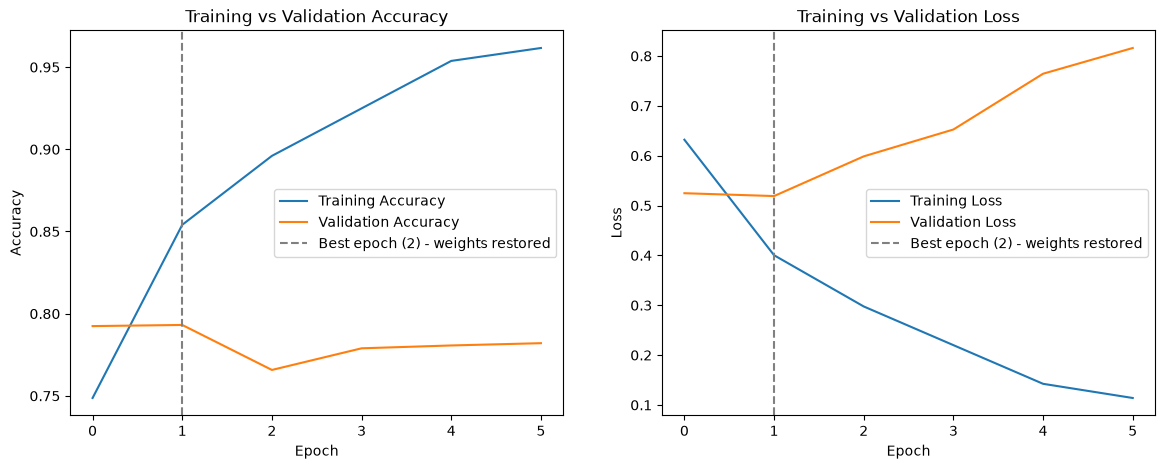

In [53]:
best_epoch = int(np.argmin(history.history['val_loss']))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history.history['accuracy'], label='Training Accuracy')
ax[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].set_title('Training vs Validation Accuracy'); ax[0].legend()

ax[1].plot(history.history['loss'], label='Training Loss')
ax[1].plot(history.history['val_loss'], label='Validation Loss')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
ax[1].set_title('Training vs Validation Loss'); ax[1].legend()

for a in ax:
    a.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch + 1}) - weights restored')
    a.legend()

plt.show()

In [54]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss     :", loss)
print("Test Accuracy :", accuracy)

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

Test Loss     : 0.5148965716362
Test Accuracy : 0.8011087775230408
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
              precision    recall  f1-score   support

    negative       0.85      0.91      0.88      1816
     neutral       0.71      0.50      0.59       612
    positive       0.71      0.75      0.73       458

    accuracy                           0.80      2886
   macro avg       0.75      0.72      0.73      2886
weighted avg       0.79      0.80      0.79      2886



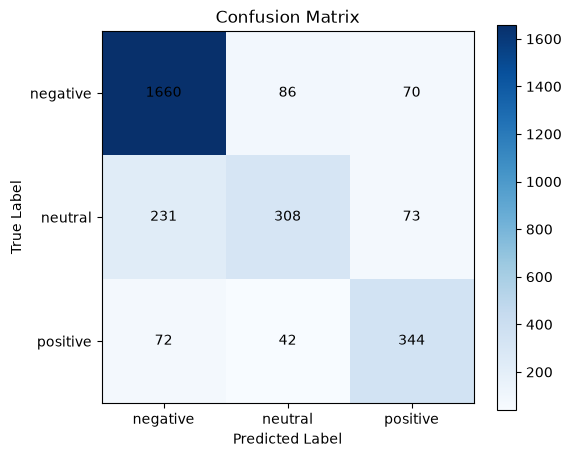

In [55]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), class_names)
plt.yticks(range(3), class_names)
plt.colorbar()

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')

plt.show()

In [56]:
def predict_sentiment(text):
    padded = encode([clean_text(text)])
    probs = model.predict(padded, verbose=0)[0]
    return class_names[int(np.argmax(probs))], probs

samples = [
    "The flight was amazing and the staff were very helpful",
    "Worst airline ever, my luggage was lost and nobody helped",
    "What time does the flight to Denver depart?"
]

for s in samples:
    label, probs = predict_sentiment(s)
    print(f"{s}\n  -> {label}  {dict(zip(class_names, probs.round(3)))}\n")

The flight was amazing and the staff were very helpful
  -> positive  {'negative': np.float32(0.012), 'neutral': np.float32(0.003), 'positive': np.float32(0.985)}

Worst airline ever, my luggage was lost and nobody helped
  -> negative  {'negative': np.float32(0.999), 'neutral': np.float32(0.001), 'positive': np.float32(0.0)}

What time does the flight to Denver depart?
  -> neutral  {'negative': np.float32(0.436), 'neutral': np.float32(0.548), 'positive': np.float32(0.016)}

